
# Indian Banking Transactions Data Preprocessing

## Business Problem
Banking transaction data may contain data quality issues such as
missing values, duplicates, inconsistent formats, invalid values,
and incorrect data types.

## Business Objective
Build a reliable and reproducible data preprocessing pipeline
using Python Pandas.

## Project Scope
1. Data ingestion
2. Data profiling
3. Missing value analysis
4. Duplicate detection
5. Data type correction
6. Data standardization
7. Invalid data analysis
8. Outlier analysis
9. Data validation
10. Data quality reporting
11. Export cleaned data

## Technology Stack
- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

## Dataset
Indian Banking Transactions

## Expected Output
A clean, validated, analysis-ready dataset.



In [ ]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

print("Libraries imported successfully!")
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)


Libraries imported successfully!
Pandas Version: 2.2.3
NumPy Version: 2.4.6


In [ ]:
df_raw = pd.read_csv('indian_banking_transactions.csv')
df_raw.head()

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764.00,0.00,NaN,0.00,Success,Branch,Verified,0.00,15.00
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630.00,0.00,NaN,0.00,Success,Mobile_App,Verified,0.00,3.00
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813.00,1.00,Home,1433.91,Success,Mobile_App,Verified,0.00,18.00
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628.00,1.00,Personal,6280.35,Success,API,Verified,0.00,8.00
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767.00,0.00,NaN,0.00,Success,API,Verified,0.00,14.00


In [ ]:
df_clean = df_raw.copy()

print("Raw dataset:", df_raw.shape)
print("Working dataset:", df_clean.shape)

Raw dataset: (144698, 20)
Working dataset: (144698, 20)


In [ ]:

# Dataset dimensions

rows, columns = df_raw.shape

print("Total Rows:", rows)
print("Total Columns:", columns)


Total Rows: 144698
Total Columns: 20


In [ ]:
df_raw.head()

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764.00,0.00,NaN,0.00,Success,Branch,Verified,0.00,15.00
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630.00,0.00,NaN,0.00,Success,Mobile_App,Verified,0.00,3.00
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813.00,1.00,Home,1433.91,Success,Mobile_App,Verified,0.00,18.00
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628.00,1.00,Personal,6280.35,Success,API,Verified,0.00,8.00
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767.00,0.00,NaN,0.00,Success,API,Verified,0.00,14.00


In [ ]:
df_raw.tail()

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
144693,TXN000144694,CUST010133,2020-04-25,18:06,Savings,RTGS,124865.98,Debit,43894.64,Insurance,Tamil Nadu,630.00,0.00,NaN,0.00,Success,API,Verified,0.00,18.00
144694,TXN000144695,CUST032909,2020-04-25,08:42,Current,ATM_Withdrawal,1000.00,Debit,45036.30,Entertainment,Tamil Nadu,854.00,1.00,Home,1107.85,Success,Mobile_App,Verified,0.00,8.00
144695,TXN000144696,CUST064144,2020-04-25,03:41,Current,ATM_Withdrawal,5000.00,Debit,7374.45,Fuel,Gujarat,423.00,0.00,NaN,0.00,Success,Mobile_App,Verified,0.00,3.00
144696,TXN000144697,CUST033439,2020-04-25,02:32,Savings,Auto_Debit,2794.40,Debit,80115.02,Insurance,Gujarat,632.00,1.00,Business,4044.40,Success,Mobile_App,Pending,0.00,2.00
144697,TXN000144698,CUST057366,2020-04-25,20:28,Current,UPI,536.43,Credit,163922.04,Fuel,Maharashtra,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# List all column names

df_raw.columns.tolist()

['transaction_id',
 'customer_id',
 'transaction_date',
 'transaction_time',
 'account_type',
 'transaction_type',
 'transaction_amount',
 'transaction_direction',
 'account_balance',
 'merchant_category',
 'state',
 'credit_score',
 'has_loan',
 'loan_type',
 'emi_amount',
 'transaction_status',
 'channel',
 'kyc_status',
 'is_fraud',
 'transaction_hour']

In [ ]:
# Dataset information

df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144698 entries, 0 to 144697
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         144698 non-null  object 
 1   customer_id            144698 non-null  object 
 2   transaction_date       144698 non-null  object 
 3   transaction_time       144698 non-null  object 
 4   account_type           144698 non-null  object 
 5   transaction_type       144698 non-null  object 
 6   transaction_amount     144698 non-null  float64
 7   transaction_direction  144698 non-null  object 
 8   account_balance        144698 non-null  float64
 9   merchant_category      144698 non-null  object 
 10  state                  144698 non-null  object 
 11  credit_score           144697 non-null  float64
 12  has_loan               144697 non-null  float64
 13  loan_type              45533 non-null   object 
 14  emi_amount             144697 non-nu

In [ ]:
# Numerical column summary

df_raw.describe()

,transaction_amount,account_balance,credit_score,has_loan,emi_amount,is_fraud,transaction_hour
count,144698.00,144698.00,144697.00,144697.00,144697.00,144697.00,144697.00
mean,29799.21,84736.41,599.74,0.35,2385.70,0.01,11.50
std,136065.83,172384.34,173.29,0.48,5048.45,0.09,6.93
min,6.24,500.00,300.00,0.00,0.00,0.00,0.00
25%,763.83,15230.27,450.00,0.00,0.00,0.00,6.00
50%,2031.64,36368.23,599.00,0.00,0.00,0.00,11.00
75%,8627.16,87601.56,750.00,1.00,3124.62,0.00,17.00
max,8455419.74,5000000.00,899.00,1.00,126816.90,1.00,23.00


In [ ]:
# Numerical and categorical summary

df_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,144698,144698,TXN000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,144698,66855,CUST000646,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,144698,481,2019-05-18,366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_time,144698,1440,00:45,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_type,144698,5,Savings,57789,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_type,144698,10,UPI,40552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_amount,144698.00,NaN,NaN,NaN,29799.21,136065.83,6.24,763.83,2031.64,8627.16,8455419.74
transaction_direction,144698,2,Debit,97313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_balance,144698.00,NaN,NaN,NaN,84736.41,172384.34,500.00,15230.27,36368.23,87601.56,5000000.00
merchant_category,144698,15,Retail,17251,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

# Create data profiling report

data_profile = pd.DataFrame({
    'Column_Name': df_raw.columns,
    'Data_Type': df_raw.dtypes.astype(str).values,
    'Total_Records': len(df_raw),
    'Missing_Values': df_raw.isnull().sum().values,
    'Unique_Values': df_raw.nunique().values
})

data_profile['Completeness_Percentage'] = (
    (data_profile['Total_Records'] -
     data_profile['Missing_Values']) /
    data_profile['Total_Records'] * 100
)

data_profile


,Column_Name,Data_Type,Total_Records,Missing_Values,Unique_Values,Completeness_Percentage
0,transaction_id,object,144698,0,144698,100.00
1,customer_id,object,144698,0,66855,100.00
2,transaction_date,object,144698,0,481,100.00
3,transaction_time,object,144698,0,1440,100.00
4,account_type,object,144698,0,5,100.00
5,transaction_type,object,144698,0,10,100.00
6,transaction_amount,float64,144698,0,119103,100.00
7,transaction_direction,object,144698,0,2,100.00
8,account_balance,float64,144698,0,143696,100.00
9,merchant_category,object,144698,0,15,100.00


In [ ]:

# Numeric columns

numerical_columns = df_raw.select_dtypes(
    include=np.number
).columns.tolist()

# Text columns

categorical_columns = df_raw.select_dtypes(
    include=['object', 'string']
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['transaction_amount', 'account_balance', 'credit_score', 'has_loan', 'emi_amount', 'is_fraud', 'transaction_hour']

Categorical Columns:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_direction', 'merchant_category', 'state', 'loan_type', 'transaction_status', 'channel', 'kyc_status']


In [ ]:

# Count missing values in each column

missing_count = df_clean.isnull().sum()

missing_count


,0
transaction_id,0
customer_id,0
transaction_date,0
transaction_time,0
account_type,0
transaction_type,0
transaction_amount,0
transaction_direction,0
account_balance,0
merchant_category,0


In [ ]:

# Missing value percentage

missing_percentage = (
    df_clean.isnull().sum() /
    len(df_clean)
) * 100

missing_percentage


,0
transaction_id,0.00
customer_id,0.00
transaction_date,0.00
transaction_time,0.00
account_type,0.00
transaction_type,0.00
transaction_amount,0.00
transaction_direction,0.00
account_balance,0.00
merchant_category,0.00


In [ ]:

# Combine missing count and percentage

missing_report = pd.DataFrame({
    'Missing_Count': df_clean.isnull().sum(),
    'Missing_Percentage': (
        df_clean.isnull().sum() /
        len(df_clean) * 100
    )
})

# Keep only columns with missing values
missing_report = missing_report[
    missing_report['Missing_Count'] > 0
]

missing_report.sort_values(
    by='Missing_Percentage',
    ascending=False
)


,Missing_Count,Missing_Percentage
loan_type,99165,68.53
credit_score,1,0.00
has_loan,1,0.00
emi_amount,1,0.00
transaction_status,1,0.00
channel,1,0.00
kyc_status,1,0.00
is_fraud,1,0.00
transaction_hour,1,0.00


In [ ]:

# Check loan status against loan type

loan_analysis = pd.crosstab(
    df_clean['has_loan'],
    df_clean['loan_type'].isnull(),
    margins=True
)

loan_analysis


loan_type,False,True,All
has_loan,,,
0.00,0,94006,94006
1.00,45533,5158,50691
All,45533,99164,144697


In [ ]:

# Records that have a loan but missing loan type

loan_type_missing_with_loan = df_clean[
    (df_clean['has_loan'] == 1) &
    (df_clean['loan_type'].isnull())
]

print(
    "Records with has_loan = 1 and missing loan_type:",
    len(loan_type_missing_with_loan)
)

loan_type_missing_with_loan.head()


Records with has_loan = 1 and missing loan_type: 5158


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
40,TXN000000041,CUST023898,2019-01-01,11:35,Savings,Auto_Debit,879.10,Debit,45807.46,E-Commerce,Delhi,633.00,1.00,NaN,8597.49,Success,Web,Verified,0.00,11.00
41,TXN000000042,CUST068149,2019-01-01,20:07,Salary,UPI,634.61,Credit,232027.81,Peer Transfer,Delhi,678.00,1.00,NaN,6697.80,Success,API,Verified,0.00,20.00
68,TXN000000069,CUST009269,2019-01-01,19:00,Current,RTGS,79938.63,Debit,199447.61,Utilities,UP,352.00,1.00,NaN,5683.47,Success,ATM,Pending,0.00,19.00
72,TXN000000073,CUST008572,2019-01-01,07:12,Savings,UPI,424.06,Debit,706365.16,E-Commerce,Maharashtra,478.00,1.00,NaN,8317.18,Success,API,Verified,0.00,7.00
109,TXN000000110,CUST052993,2019-01-01,14:02,Current,Credit_Card,834.03,Debit,66941.13,E-Commerce,West Bengal,841.00,1.00,NaN,6982.45,Success,ATM,Verified,0.00,14.00


In [ ]:

# Count exact duplicate rows

duplicate_count = df_clean.duplicated().sum()

print("Total Exact Duplicate Records:", duplicate_count)


Total Exact Duplicate Records: 0


In [ ]:

# Display all duplicate occurrences

duplicate_records = df_clean[
    df_clean.duplicated(keep=False)
]

duplicate_records.head(10)


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour


In [ ]:

# Check duplicate transaction IDs

duplicate_transaction_ids = df_clean[
    df_clean['transaction_id'].duplicated(keep=False)
].sort_values('transaction_id')

print(
    "Duplicate Transaction ID Records:",
    len(duplicate_transaction_ids)
)

duplicate_transaction_ids.head(10)


Duplicate Transaction ID Records: 0


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour


In [ ]:

# Remove exact duplicate records

before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

after_duplicates = len(df_clean)

print("Rows Before:", before_duplicates)
print("Rows After:", after_duplicates)
print("Removed Rows:", before_duplicates - after_duplicates)


Rows Before: 144698
Rows After: 144698
Removed Rows: 0


In [ ]:

# Verify exact duplicates

print(
    "Remaining Exact Duplicates:",
    df_clean.duplicated().sum()
)

# Verify transaction ID uniqueness
print(
    "Duplicate Transaction IDs:",
    df_clean['transaction_id'].duplicated().sum()
)


Remaining Exact Duplicates: 0
Duplicate Transaction IDs: 0


In [ ]:

df_clean.dtypes


,0
transaction_id,object
customer_id,object
transaction_date,object
transaction_time,object
account_type,object
transaction_type,object
transaction_amount,float64
transaction_direction,object
account_balance,float64
merchant_category,object


In [ ]:

# Convert transaction date

df_clean['transaction_date'] = pd.to_datetime(
    df_clean['transaction_date'],
    errors='coerce'
)

print(
    "Transaction Date Data Type:",
    df_clean['transaction_date'].dtype
)


Transaction Date Data Type: datetime64[ns]


In [ ]:

# Convert transaction time to a consistent string format

df_clean['transaction_time'] = (
    df_clean['transaction_time']
    .astype('string')
    .str.strip()
)

# Validate time format HH:MM
df_clean['transaction_time'] = pd.to_datetime(
    df_clean['transaction_time'],
    format='%H:%M',
    errors='coerce'
).dt.strftime('%H:%M')

print("Transaction time standardized.")


Transaction time standardized.


In [ ]:

# Numeric columns to convert

numeric_columns_to_convert = [
    'transaction_amount',
    'account_balance',
    'credit_score',
    'has_loan',
    'emi_amount',
    'is_fraud',
    'transaction_hour'
]

for col in numeric_columns_to_convert:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors='coerce'
    )

print("Numeric data type conversion completed.")


Numeric data type conversion completed.


In [ ]:

# Convert identifier columns to string

id_columns = [
    'transaction_id',
    'customer_id'
]

for col in id_columns:
    df_clean[col] = df_clean[col].astype('string')

print("ID columns converted to string.")


ID columns converted to string.


In [ ]:

# Verify data types after conversion

df_clean.dtypes


,0
transaction_id,string[python]
customer_id,string[python]
transaction_date,datetime64[ns]
transaction_time,object
account_type,object
transaction_type,object
transaction_amount,float64
transaction_direction,object
account_balance,float64
merchant_category,object


In [ ]:

# Identify categorical columns

text_columns = [
    'account_type',
    'transaction_type',
    'transaction_direction',
    'merchant_category',
    'state',
    'loan_type',
    'transaction_status',
    'channel',
    'kyc_status'
]

print(text_columns)


['account_type', 'transaction_type', 'transaction_direction', 'merchant_category', 'state', 'loan_type', 'transaction_status', 'channel', 'kyc_status']


In [ ]:

# Strip whitespace from categorical values

for col in text_columns:
    df_clean[col] = (
        df_clean[col]
        .astype('string')
        .str.strip()
    )

print("Whitespace standardization completed.")


Whitespace standardization completed.


In [ ]:

# Standardize categorical text to uppercase

for col in text_columns:
    df_clean[col] = df_clean[col].str.upper()

print("Categorical values standardized.")


Categorical values standardized.


In [ ]:

# Inspect unique values in each category

for col in text_columns:
    print(f"\nColumn: {col}")
    print(df_clean[col].value_counts(dropna=False))



Column: account_type
account_type
SAVINGS          57789
CURRENT          36436
SALARY           28787
NRI              11472
FIXED DEPOSIT    10214
Name: count, dtype: Int64

Column: transaction_type
transaction_type
UPI               40552
IMPS              20282
NEFT              17485
POS               15798
ATM_WITHDRAWAL    14493
NET_BANKING       10048
RTGS               8702
AUTO_DEBIT         7228
CHEQUE             5709
CREDIT_CARD        4401
Name: count, dtype: Int64

Column: transaction_direction
transaction_direction
DEBIT     97313
CREDIT    47385
Name: count, dtype: Int64

Column: merchant_category
merchant_category
RETAIL           17251
E-COMMERCE       14722
FOOD & DINING    14364
TRAVEL           11680
SALARY           11460
PEER TRANSFER    10167
UTILITIES         9983
ENTERTAINMENT     8755
HEALTHCARE        8589
INVESTMENT        7314
EDUCATION         7223
GOVERNMENT        7139
INSURANCE         5820
FUEL              5744
REAL ESTATE       4487
Name: count, d

In [ ]:

# Display standardized records

df_clean[text_columns].head(10)


,account_type,transaction_type,transaction_direction,merchant_category,state,loan_type,transaction_status,channel,kyc_status
0,CURRENT,UPI,DEBIT,FOOD & DINING,MAHARASHTRA,<NA>,SUCCESS,BRANCH,VERIFIED
1,CURRENT,UPI,CREDIT,EDUCATION,WEST BENGAL,<NA>,SUCCESS,MOBILE_APP,VERIFIED
2,FIXED DEPOSIT,POS,DEBIT,UTILITIES,PUNJAB,HOME,SUCCESS,MOBILE_APP,VERIFIED
3,SAVINGS,UPI,DEBIT,TRAVEL,KARNATAKA,PERSONAL,SUCCESS,API,VERIFIED
4,FIXED DEPOSIT,UPI,DEBIT,UTILITIES,WEST BENGAL,<NA>,SUCCESS,API,VERIFIED
5,FIXED DEPOSIT,NET_BANKING,DEBIT,GOVERNMENT,KARNATAKA,AUTO,PENDING,WEB,VERIFIED
6,SAVINGS,NEFT,CREDIT,INVESTMENT,PUNJAB,HOME,SUCCESS,ATM,VERIFIED
7,CURRENT,NET_BANKING,DEBIT,HEALTHCARE,PUNJAB,<NA>,SUCCESS,MOBILE_APP,EXPIRED
8,SALARY,CREDIT_CARD,DEBIT,FOOD & DINING,TAMIL NADU,<NA>,SUCCESS,WEB,VERIFIED
9,SAVINGS,NET_BANKING,DEBIT,REAL ESTATE,KARNATAKA,PERSONAL,SUCCESS,WEB,VERIFIED


In [ ]:

# Identify zero and negative transaction amounts

invalid_amounts = df_clean[
    df_clean['transaction_amount'] <= 0
]

print("Zero or Negative Amount Records:", len(invalid_amounts))

invalid_amounts.head(10)


Zero or Negative Amount Records: 0


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour


In [ ]:

# Identify missing transaction amounts

missing_amount_records = df_clean[
    df_clean['transaction_amount'].isnull()
]

print("Missing Amount Records:", len(missing_amount_records))


Missing Amount Records: 0


In [ ]:

# Identify invalid credit scores

invalid_credit_scores = df_clean[
    (df_clean['credit_score'] < 300) |
    (df_clean['credit_score'] > 900) |
    (df_clean['credit_score'].isnull())
]

print("Invalid Credit Score Records:", len(invalid_credit_scores))

invalid_credit_scores.head()


Invalid Credit Score Records: 1


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
144697,TXN000144698,CUST057366,2020-04-25,20:28,CURRENT,UPI,536.43,CREDIT,163922.04,FUEL,MAHARASHTRA,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,NaN,NaN


In [ ]:

# has_loan should be 0 or 1

invalid_loan_indicators = df_clean[
    ~df_clean['has_loan'].isin([0, 1])
]

print("Invalid has_loan Records:", len(invalid_loan_indicators))


Invalid has_loan Records: 1


In [ ]:

# is_fraud should be 0 or 1

invalid_fraud_indicators = df_clean[
    ~df_clean['is_fraud'].isin([0, 1])
]

print("Invalid is_fraud Records:", len(invalid_fraud_indicators))


Invalid is_fraud Records: 1


In [ ]:

# transaction_hour must be from 0 to 23

invalid_transaction_hours = df_clean[
    (df_clean['transaction_hour'] < 0) |
    (df_clean['transaction_hour'] > 23) |
    (df_clean['transaction_hour'].isnull())
]

print("Invalid Transaction Hours:", len(invalid_transaction_hours))


Invalid Transaction Hours: 1


In [ ]:

# Identify invalid dates converted to NaT

invalid_dates = df_clean[
    df_clean['transaction_date'].isnull()
]

print("Invalid Transaction Dates:", len(invalid_dates))


Invalid Transaction Dates: 0


In [ ]:

# Allowed transaction statuses

valid_statuses = [
    'SUCCESS',
    'FAILED',
    'REVERSED',
    'PENDING'
]

invalid_statuses = df_clean[
    ~df_clean['transaction_status'].isin(valid_statuses)
]

print("Invalid Transaction Status Records:", len(invalid_statuses))

invalid_statuses.head()


Invalid Transaction Status Records: 1


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
144697,TXN000144698,CUST057366,2020-04-25,20:28,CURRENT,UPI,536.43,CREDIT,163922.04,FUEL,MAHARASHTRA,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,NaN,NaN


In [ ]:

# Loan type present when has_loan = 0

loan_type_without_loan = df_clean[
    (df_clean['has_loan'] == 0) &
    (df_clean['loan_type'].notnull())
]

# Loan type missing when has_loan = 1

loan_type_missing_for_loan = df_clean[
    (df_clean['has_loan'] == 1) &
    (df_clean['loan_type'].isnull())
]

print(
    "Loan type present without loan:",
    len(loan_type_without_loan)
)

print(
    "Loan type missing for loan:",
    len(loan_type_missing_for_loan)
)


Loan type present without loan: 0
Loan type missing for loan: 5158


In [ ]:

# Create invalid data report

invalid_data_report = pd.DataFrame({
    'Issue': [
        'Zero or Negative Transaction Amount',
        'Missing Transaction Amount',
        'Invalid Credit Score',
        'Invalid Loan Indicator',
        'Invalid Fraud Indicator',
        'Invalid Transaction Hour',
        'Invalid Transaction Date',
        'Invalid Transaction Status',
        'Loan Type Present Without Loan',
        'Loan Type Missing For Loan'
    ],
    'Count': [
        len(invalid_amounts),
        len(missing_amount_records),
        len(invalid_credit_scores),
        len(invalid_loan_indicators),
        len(invalid_fraud_indicators),
        len(invalid_transaction_hours),
        len(invalid_dates),
        len(invalid_statuses),
        len(loan_type_without_loan),
        len(loan_type_missing_for_loan)
    ]
})

invalid_data_report


,Issue,Count
0,Zero or Negative Transaction Amount,0
1,Missing Transaction Amount,0
2,Invalid Credit Score,1
3,Invalid Loan Indicator,1
4,Invalid Fraud Indicator,1
5,Invalid Transaction Hour,1
6,Invalid Transaction Date,0
7,Invalid Transaction Status,1
8,Loan Type Present Without Loan,0
9,Loan Type Missing For Loan,5158


In [ ]:

# Analyze transaction amount distribution

df_clean['transaction_amount'].describe()


,transaction_amount
count,144698.00
mean,29799.21
std,136065.83
min,6.24
25%,763.83
50%,2031.64
75%,8627.16
max,8455419.74


In [ ]:

# Calculate quartiles

Q1 = df_clean['transaction_amount'].quantile(0.25)

Q3 = df_clean['transaction_amount'].quantile(0.75)

# Calculate Interquartile Range

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)


Q1: 763.825
Q3: 8627.1625
IQR: 7863.337500000001


In [ ]:

# Calculate lower and upper bounds

lower_bound = Q1 - (1.5 * IQR)

upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)


Lower Bound: -11031.18125
Upper Bound: 20422.16875


In [ ]:

# Identify statistical outliers

outliers = df_clean[
    (df_clean['transaction_amount'] < lower_bound) |
    (df_clean['transaction_amount'] > upper_bound)
]

print("Total Outliers:", len(outliers))

outliers.head(10)


Total Outliers: 23404


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
5,TXN000000006,CUST037195,2019-01-01,01:51,FIXED DEPOSIT,NET_BANKING,39172.48,DEBIT,1798.86,GOVERNMENT,KARNATAKA,707.00,1.00,AUTO,4197.37,PENDING,WEB,VERIFIED,0.00,1.00
10,TXN000000011,CUST067222,2019-01-01,08:50,SALARY,CHEQUE,95223.86,DEBIT,200239.14,GOVERNMENT,MAHARASHTRA,358.00,0.00,<NA>,0.00,SUCCESS,MOBILE_APP,VERIFIED,0.00,8.00
16,TXN000000017,CUST067970,2019-01-01,10:55,SAVINGS,NEFT,60788.40,CREDIT,119463.69,GOVERNMENT,PUNJAB,525.00,0.00,<NA>,0.00,SUCCESS,BRANCH,VERIFIED,0.00,10.00
20,TXN000000021,CUST071933,2019-01-01,18:37,CURRENT,RTGS,24601.60,DEBIT,25884.35,E-COMMERCE,UP,890.00,1.00,GOLD,9645.10,SUCCESS,WEB,VERIFIED,0.00,18.00
21,TXN000000022,CUST025659,2019-01-01,05:29,CURRENT,RTGS,73416.02,CREDIT,21042.96,TRAVEL,RAJASTHAN,862.00,0.00,<NA>,0.00,SUCCESS,MOBILE_APP,VERIFIED,0.00,5.00
25,TXN000000026,CUST065726,2019-01-01,16:43,SAVINGS,NET_BANKING,24752.78,CREDIT,24426.00,RETAIL,DELHI,738.00,0.00,<NA>,0.00,SUCCESS,WEB,VERIFIED,0.00,16.00
35,TXN000000036,CUST010628,2019-01-01,13:07,SALARY,CREDIT_CARD,41717.68,DEBIT,25147.14,ENTERTAINMENT,UP,372.00,0.00,<NA>,0.00,SUCCESS,MOBILE_APP,VERIFIED,0.00,13.00
38,TXN000000039,CUST043002,2019-01-01,23:04,CURRENT,IMPS,37391.94,CREDIT,27586.27,E-COMMERCE,DELHI,614.00,0.00,<NA>,0.00,SUCCESS,BRANCH,VERIFIED,0.00,23.00
54,TXN000000055,CUST009693,2019-01-01,18:28,SALARY,RTGS,28438.49,CREDIT,34822.82,SALARY,WEST BENGAL,789.00,0.00,<NA>,0.00,SUCCESS,MOBILE_APP,VERIFIED,0.00,18.00
55,TXN000000056,CUST045759,2019-01-01,12:35,NRI,CREDIT_CARD,27986.94,DEBIT,13297.80,E-COMMERCE,MAHARASHTRA,711.00,1.00,PERSONAL,3887.80,SUCCESS,WEB,VERIFIED,0.00,12.00


In [ ]:

# Calculate outlier percentage

outlier_percentage = (
    len(outliers) / len(df_clean)
) * 100

print("Total Records:", len(df_clean))
print("Outlier Records:", len(outliers))
print("Outlier Percentage:", round(outlier_percentage, 2), "%")


Total Records: 144698
Outlier Records: 23404
Outlier Percentage: 16.17 %


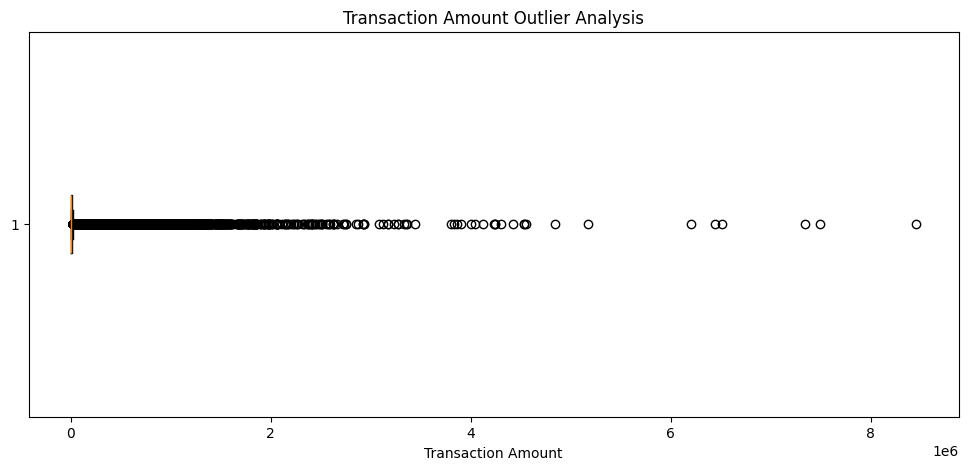

In [ ]:

# Create boxplot

plt.figure(figsize=(12, 5))

plt.boxplot(
    df_clean['transaction_amount'].dropna(),
    vert=False
)

plt.title('Transaction Amount Outlier Analysis')
plt.xlabel('Transaction Amount')

plt.show()


In [ ]:

# Check transaction ID uniqueness

transaction_id_unique = (
    df_clean['transaction_id'].is_unique
)

print("Transaction IDs Unique:", transaction_id_unique)


Transaction IDs Unique: True


In [ ]:

# Verify expected data types

expected_dtypes = {
    'transaction_id': 'string',
    'customer_id': 'string',
    'transaction_date': 'datetime64[ns]',
    'transaction_amount': 'float64',
    'account_balance': 'float64'
}

for col, expected_dtype in expected_dtypes.items():

    actual_dtype = str(df_clean[col].dtype)

    print(
        f"{col}: Expected={expected_dtype}, "
        f"Actual={actual_dtype}, "
        f"Pass={actual_dtype == expected_dtype}"
    )


transaction_id: Expected=string, Actual=string, Pass=True
customer_id: Expected=string, Actual=string, Pass=True
transaction_date: Expected=datetime64[ns], Actual=datetime64[ns], Pass=True
transaction_amount: Expected=float64, Actual=float64, Pass=True
account_balance: Expected=float64, Actual=float64, Pass=True


In [ ]:

# Allowed transaction status values

allowed_transaction_status = [
    'SUCCESS',
    'FAILED',
    'REVERSED',
    'PENDING'
]

# Identify invalid values

invalid_status_values = df_clean[
    ~df_clean['transaction_status'].isin(
        allowed_transaction_status
    )
]

print("Invalid Status Values:", len(invalid_status_values))


Invalid Status Values: 1


In [ ]:

# Check missing transaction amounts

missing_transaction_amounts = (
    df_clean['transaction_amount'].isnull().sum()
)

# Check non-positive amounts

non_positive_amounts = (
    (df_clean['transaction_amount'] <= 0).sum()
)

print("Missing Amounts:", missing_transaction_amounts)
print("Non-Positive Amounts:", non_positive_amounts)


Missing Amounts: 0
Non-Positive Amounts: 0


In [ ]:

# Validate transaction dates

invalid_transaction_dates = (
    df_clean['transaction_date'].isnull().sum()
)

# Validate transaction time format HH:MM

invalid_transaction_times = (
    df_clean['transaction_time'].isnull().sum()
)

print("Invalid Transaction Dates:", invalid_transaction_dates)
print("Invalid Transaction Times:", invalid_transaction_times)


Invalid Transaction Dates: 0
Invalid Transaction Times: 0


In [ ]:

# Create validation report

validation_report = pd.DataFrame({
    'Validation_Check': [
        'Transaction ID Uniqueness',
        'Exact Duplicate Records',
        'Missing Transaction Amounts',
        'Non-Positive Transaction Amounts',
        'Invalid Transaction Dates',
        'Invalid Transaction Times',
        'Invalid Transaction Statuses',
        'Invalid Credit Scores',
        'Invalid Loan Indicators',
        'Invalid Fraud Indicators',
        'Invalid Transaction Hours'
    ],
    'Issue_Count': [
        df_clean['transaction_id'].duplicated().sum(),
        df_clean.duplicated().sum(),
        df_clean['transaction_amount'].isnull().sum(),
        (df_clean['transaction_amount'] <= 0).sum(),
        df_clean['transaction_date'].isnull().sum(),
        df_clean['transaction_time'].isnull().sum(),
        len(invalid_statuses),
        len(invalid_credit_scores),
        len(invalid_loan_indicators),
        len(invalid_fraud_indicators),
        len(invalid_transaction_hours)
    ]
})

validation_report['Status'] = np.where(
    validation_report['Issue_Count'] == 0,
    'PASS',
    'REVIEW'
)

validation_report


,Validation_Check,Issue_Count,Status
0,Transaction ID Uniqueness,0,PASS
1,Exact Duplicate Records,0,PASS
2,Missing Transaction Amounts,0,PASS
3,Non-Positive Transaction Amounts,0,PASS
4,Invalid Transaction Dates,0,PASS
5,Invalid Transaction Times,0,PASS
6,Invalid Transaction Statuses,1,REVIEW
7,Invalid Credit Scores,1,REVIEW
8,Invalid Loan Indicators,1,REVIEW
9,Invalid Fraud Indicators,1,REVIEW


In [ ]:

# Final data quality summary

quality_summary = pd.DataFrame({
    'Metric': [
        'Original Row Count',
        'Cleaned Row Count',
        'Original Column Count',
        'Exact Duplicates Removed',
        'Remaining Exact Duplicates',
        'Missing Values After Processing',
        'Transaction ID Duplicate Count',
        'Statistical Outlier Count'
    ],
    'Value': [
        len(df_raw),
        len(df_clean),
        df_raw.shape[1],
        len(df_raw) - len(df_clean),
        df_clean.duplicated().sum(),
        df_clean.isnull().sum().sum(),
        df_clean['transaction_id'].duplicated().sum(),
        len(outliers)
    ]
})

quality_summary


,Metric,Value
0,Original Row Count,144698
1,Cleaned Row Count,144698
2,Original Column Count,20
3,Exact Duplicates Removed,0
4,Remaining Exact Duplicates,0
5,Missing Values After Processing,99173
6,Transaction ID Duplicate Count,0
7,Statistical Outlier Count,23404


In [ ]:

# Display first 10 rows of final dataset

df_clean.head(10)


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,CURRENT,UPI,1820.17,DEBIT,609365.31,FOOD & DINING,MAHARASHTRA,764.00,0.00,<NA>,0.00,SUCCESS,BRANCH,VERIFIED,0.00,15.00
1,TXN000000002,CUST000861,2019-01-01,03:00,CURRENT,UPI,392.67,CREDIT,14451.14,EDUCATION,WEST BENGAL,630.00,0.00,<NA>,0.00,SUCCESS,MOBILE_APP,VERIFIED,0.00,3.00
2,TXN000000003,CUST076821,2019-01-01,18:03,FIXED DEPOSIT,POS,1255.97,DEBIT,47621.87,UTILITIES,PUNJAB,813.00,1.00,HOME,1433.91,SUCCESS,MOBILE_APP,VERIFIED,0.00,18.00
3,TXN000000004,CUST054887,2019-01-01,08:03,SAVINGS,UPI,2580.68,DEBIT,34467.85,TRAVEL,KARNATAKA,628.00,1.00,PERSONAL,6280.35,SUCCESS,API,VERIFIED,0.00,8.00
4,TXN000000005,CUST006266,2019-01-01,14:23,FIXED DEPOSIT,UPI,2573.80,DEBIT,26617.40,UTILITIES,WEST BENGAL,767.00,0.00,<NA>,0.00,SUCCESS,API,VERIFIED,0.00,14.00
5,TXN000000006,CUST037195,2019-01-01,01:51,FIXED DEPOSIT,NET_BANKING,39172.48,DEBIT,1798.86,GOVERNMENT,KARNATAKA,707.00,1.00,AUTO,4197.37,PENDING,WEB,VERIFIED,0.00,1.00
6,TXN000000007,CUST044132,2019-01-01,06:27,SAVINGS,NEFT,4008.09,CREDIT,177668.37,INVESTMENT,PUNJAB,361.00,1.00,HOME,4251.79,SUCCESS,ATM,VERIFIED,0.00,6.00
7,TXN000000008,CUST060264,2019-01-01,23:40,CURRENT,NET_BANKING,17797.85,DEBIT,17568.23,HEALTHCARE,PUNJAB,651.00,0.00,<NA>,0.00,SUCCESS,MOBILE_APP,EXPIRED,0.00,23.00
8,TXN000000009,CUST016024,2019-01-01,20:25,SALARY,CREDIT_CARD,3284.62,DEBIT,66973.00,FOOD & DINING,TAMIL NADU,443.00,0.00,<NA>,0.00,SUCCESS,WEB,VERIFIED,0.00,20.00
9,TXN000000010,CUST041091,2019-01-01,22:15,SAVINGS,NET_BANKING,921.64,DEBIT,36054.94,REAL ESTATE,KARNATAKA,330.00,1.00,PERSONAL,9630.13,SUCCESS,WEB,VERIFIED,0.00,22.00


In [ ]:

# Final dataset information

df_clean.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144698 entries, 0 to 144697
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   transaction_id         144698 non-null  string        
 1   customer_id            144698 non-null  string        
 2   transaction_date       144698 non-null  datetime64[ns]
 3   transaction_time       144698 non-null  object        
 4   account_type           144698 non-null  string        
 5   transaction_type       144698 non-null  string        
 6   transaction_amount     144698 non-null  float64       
 7   transaction_direction  144698 non-null  string        
 8   account_balance        144698 non-null  float64       
 9   merchant_category      144698 non-null  string        
 10  state                  144698 non-null  string        
 11  credit_score           144697 non-null  float64       
 12  has_loan               144697 non-null  floa

In [ ]:

# Check final rows and columns

print("Final Dataset Shape:", df_clean.shape)
print("Total Rows:", df_clean.shape[0])
print("Total Columns:", df_clean.shape[1])


Final Dataset Shape: (144698, 20)
Total Rows: 144698
Total Columns: 20


In [ ]:

# Export cleaned dataset

output_file = 'indian_banking_transactions_cleaned.csv'

df_clean.to_csv(
    output_file,
    index=False
)

print("Cleaned dataset exported successfully!")
print("File Name:", output_file)


Cleaned dataset exported successfully!
File Name: indian_banking_transactions_cleaned.csv


In [ ]:

# Export data quality reports

data_profile.to_csv(
    'data_profiling_report.csv',
    index=False
)

missing_report.to_csv(
    'missing_value_report.csv'
)

invalid_data_report.to_csv(
    'invalid_data_report.csv',
    index=False
)

outlier_report = pd.DataFrame({
    'Metric': [
        'Q1',
        'Q3',
        'IQR',
        'Lower Bound',
        'Upper Bound',
        'Total Outliers',
        'Outlier Percentage'
    ],
    'Value': [
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        len(outliers),
        outlier_percentage
    ]
})

outlier_report.to_csv(
    'outlier_analysis_report.csv',
    index=False
)

validation_report.to_csv(
    'data_validation_report.csv',
    index=False
)

quality_summary.to_csv(
    'final_data_quality_summary.csv',
    index=False
)

print("All data quality reports exported successfully!")


All data quality reports exported successfully!


In [ ]:

# Download cleaned CSV from Google Colab

from google.colab import files

files.download(
    'indian_banking_transactions_cleaned.csv'
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Download validation report

files.download(
    'data_validation_report.csv'
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>